In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import os
import pandas as pd

from matplotlib import cm
import plotly.graph_objects as go

from eazy import photoz
from eazy import hdf5 as eazyh5

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

from scipy import stats

In [2]:
main_dir = "/Users/jordan/Documents/Epochs/source_inject/"
fname = "smiles"

In [216]:
astro_cat = pd.read_csv(
    os.path.join(main_dir, fname, f"{fname}_mock_cat.csv")
)
pro_fake_segstats = pd.read_csv(
    os.path.join(main_dir, fname, f"{fname}_mock_all_segstats.csv")
)
pro_recovered_segstats = pd.read_csv(
    os.path.join(main_dir, fname, f"{fname}_mock_recovered_segstats.csv")
)

In [212]:
eazy_out = eazyh5.initialize_from_hdf5(
    h5file=os.path.join(main_dir, fname, fname, f"{fname}_zphot.out.h5")
)

set param: ADD_CGM y
set param: APPLY_IGM y
set param: APPLY_PRIOR y
set param: ARRAY_NBITS 32.0
set param: BINARY_OUTPUT y
set param: CACHE_FILE photz.tempfilt
set param: CATALOG_FILE /Users/jordan/Documents/Epochs/source_inject/smiles/smiles_mock_eazy_photometry.csv
set param: CATALOG_FORMAT ascii.commented_header
set param: CAT_HAS_EXTCORR True
set param: CHI2_SCALE 1.0
set param: DUMP_TEMPLATE_CACHE n
set param: FILTERS_RES FILTER.RES.latest
set param: FILTER_FORMAT 1.0
set param: FITTER nnls
set param: FIX_ZSPEC n
set param: GET_ZP_OFFSETS n
set param: H0 70.0
set param: HESS_THRESHOLD 1.0
set param: IGM_SCALE_TAU 1.0
set param: MAGNITUDES n
set param: MAIN_OUTPUT_FILE /Users/jordan/Documents/Epochs/source_inject/smiles/smiles/smiles_zphot.out
set param: MW_EBV 0.0
set param: NMF_TOLERANCE 0.0001
set param: NOT_OBS_THRESHOLD -90
set param: N_MIN_COLORS 3
set param: OBS_SED_FILE n
set param: OMEGA_L 0.7
set param: OMEGA_M 0.3
set param: OUTPUT_DIRECTORY /Users/jordan/Documents/Epoc

TemplateGrid: user-provided tempfilt_data
Process templates: 0.069 s


371it [00:00, 821.86it/s]


h5: read tweak_fsps_QSF_12_v3_001.dat
h5: read tweak_fsps_QSF_12_v3_002.dat
h5: read tweak_fsps_QSF_12_v3_003.dat
h5: read tweak_fsps_QSF_12_v3_004.dat
h5: read tweak_fsps_QSF_12_v3_005.dat
h5: read tweak_fsps_QSF_12_v3_006.dat
h5: read tweak_fsps_QSF_12_v3_007.dat
h5: read tweak_fsps_QSF_12_v3_008.dat
h5: read tweak_fsps_QSF_12_v3_009.dat
h5: read tweak_fsps_QSF_12_v3_010.dat
h5: read tweak_fsps_QSF_12_v3_011.dat
h5: read tweak_fsps_QSF_12_v3_012.dat
h5: read binc100z001age6_cloudy.dat
h5: read binc100z001age65_cloudy.dat
h5: read binc100z001age7_cloudy.dat
h5: read binc100z001age6.dat
h5: read binc100z001age65.dat
h5: read binc100z001age7.dat
fit_best: 0.3 s (n_proc=1,  NOBJ=9620)


In [213]:
def compute_sigmaNMAD(zspec, zphot):
    deltaz = zphot - zspec
    sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec) ) )
    return sigmaNMAD


def compute_outliers(zspec, zphot):
    sigma = compute_sigmaNMAD(zspec, zphot)
    deltaz = abs(zphot - zspec)

    Noutlier = sum(deltaz/(1+zspec) > 3*sigma)

    if len(zspec) <= 0:
        outlier_frac = 0
    else:
        outlier_frac = Noutlier / len(zspec)

    return outlier_frac, Noutlier, len(zspec)

def compute_outliers_old(zspec, zphot):
    thresh = 0.15

    deltaz = abs(zphot - zspec)
    Noutlier = sum(deltaz > thresh * (1+zspec))
    print(Noutlier)
    print(len(zspec))
    outlier_frac = Noutlier / len(zspec)
    return outlier_frac

def compute_Nsigma_outliers(zspec, zphot, zphot_err, thresh = 2.0):

    deltaz = (abs(zphot - zspec))/zphot_err
    outlier_frac = sum(deltaz >= thresh) / len(zspec)
    
    return outlier_frac

In [ ]:
zbins = np.arange(0, 40, 1.0)
zmids = (zbins[1:] + zbins[:-1])/2.0

magbins = np.arange(10, 40, 1.0)
magmids = (magbins[1:] + magbins[:-1])/2.0

completeness_array = np.zeros(shape = (len(magmids), len(zmids)))
contamination_array = np.zeros(shape = (len(magmids), len(zmids)))

for i in range(len(magmids)):
    for j in range(len(zmids)):

        detect_idx = (astro_cat["recoveredmag"] >= magbins[i]) & (astro_cat["recoveredmag"] < magbins[i+1]) & \
            (eazy_out.zbest >= zbins[j]) & (eazy_out.zbest < zbins[j+1])
        
        true_idx = (astro_cat["detmag"] >= magbins[i]) & (astro_cat["detmag"] < magbins[i+1]) & \
            (astro_cat["z"] >= zbins[j]) & (astro_cat["z"] < zbins[j+1])

        idx_bad_fit = (1 - stats.chi2.cdf(match_chi2[detect_idx], df = Nfluxes[detect_idx] - Ntemplates[detect_idx] - 1.0) < 0.05) | (eazy_out.zbest[detect_idx] == -1) | (astro_cat["detected"][detect_idx] == 0)

        outliers = compute_outliers(
            zphot=eazy_out.zbest[detect_idx][~idx_bad_fit],
            zspec=astro_cat["z"][detect_idx][~idx_bad_fit]
        )

        Nselect = np.sum(~idx_bad_fit) - outliers[1]
        Ntrue = np.sum(true_idx)
        completeness = Nselect / Ntrue
    
        if Ntrue == 0:
            completeness = np.nan
        completeness_array[i,j] = completeness
        completeness_array[i,j] = completeness

In [227]:
pro_fake_segstats["Decmax"]

0      -27.806131
1      -27.845591
2      -27.814247
3      -27.837171
4      -27.814758
          ...    
9588   -27.822370
9589   -27.776002
9590   -27.806964
9591   -27.778152
9592   -27.812029
Name: Decmax, Length: 9593, dtype: float64

In [231]:
catalogue = SkyCoord(ra=pro_fake_segstats["RAmax"].values*u.degree, dec=pro_fake_segstats["Decmax"].values*u.degree)
c = SkyCoord(
    ra=astro_cat["RA"].values*u.degree, 
    dec=astro_cat["DEC"].values*u.degree
)
idx, d2d, d3d = c.match_to_catalog_sky(catalogue)
sep_constraint = d2d <= 0.3*u.arcsec

print(sum(sep_constraint))
print(recovered_cat.shape)

6359
(6273, 62)


In [ ]:
zbins = np.arange(0, 40, 1.0)
zmids = (zbins[1:] + zbins[:-1])/2.0

magbins = np.arange(10, 40, 1.0)
magmids = (magbins[1:] + magbins[:-1])/2.0

completeness_array = np.zeros(shape = (len(magmids), len(zmids)))
contamination_array = np.zeros(shape = (len(magmids), len(zmids)))

for i in range(len(magmids)):
    for j in range(len(zmids)):

        # check if we have detected the above galaxies in the mag bin
        detect_mag_idx = (pro_recovered_segstats["mag"] >= magbins[i]) & (pro_recovered_segstats["mag"] < magbins[i+1])
        true_mag_idx = (astro_cat["detmag"] >= magbins[i]) & (astro_cat["detmag"] < magbins[i+1])
        
        catalogue = SkyCoord(
            ra=pro_fake_segstats["RAmax"][detect_mag_idx]*u.degree, 
            dec=pro_fake_segstats["Decmax"][detect_mag_idx]*u.degree,
        )
        c = SkyCoord(
            ra=astro_cat["RA"][true_mag_idx]*u.degree, 
            dec=astro_cat["DEC"][true_mag_idx]*u.degree
        )
        idx, d2d, d3d = c.match_to_catalog_sky(catalogue)
        sep_constraint = d2d < 0.3*u.arcsec

        N_mag_contaminants = sum(detect_mag_idx) - sum(sep_constraint)

        detect_idx = (pro_recovered_segstats["mag"] >= magbins[i]) & (pro_recovered_segstats["mag"] < magbins[i+1]) & \
            (eazy_out.zbest >= zbins[j]) & (eazy_out.zbest < zbins[j+1])
        
        true_idx = (astro_cat["detmag"] >= magbins[i]) & (astro_cat["detmag"] < magbins[i+1]) & \
            (astro_cat["z"] >= zbins[j]) & (astro_cat["z"] < zbins[j+1])
        
        zeazy = eazy_out.zbest[detect_idx][sep_constraint]
        ztrue = astro_cat["z"][true_idx][sep_constraint]

        chi2 = match_chi2[detect_idx][sep_constraint]
        doF = Nfluxes[detect_idx][sep_constraint] - Ntemplates[detect_idx][sep_constraint] - 1.0

        idx_bad_fit = (1 - stats.chi2.cdf(chi2, df = doF) < 0.05) | (zeazy == -1)

        zeazy_good = zeazy[~idx_bad_fit]
        ztrue_good = ztrue[~idx_bad_fit]
        
        Nselect = len(zeazy_good)
        Ncontaminants = sum(detect_idx) - Nselect
        Ntrue = sum(true_idx)

        if Ntrue == 0:
            completeness = np.nan
        completeness_array[i,j] = Nselect/Ntrue
        contamination_array[i,j] = Ncontaminants/Ntrue

IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

In [ ]:
match_chi2 = eazy_out.chi2_best

Ntemplates = np.sum(eazy_out.coeffs_best > 0, axis = 1)
Nfluxes = np.sum(eazy_out.efnu > -90, axis = 1)

## do Chi2 GOF test 
idx_bad_fit = (1 - stats.chi2.cdf(match_chi2, df = Nfluxes - Ntemplates - 1.0) < 0.05) | (eazy_out.zbest == -1) | (astro_cat["detected"] == 0)

In [116]:
zmin = 2.0
zmax = 9.0

idx_selected = (~idx_bad_fit)

In [117]:
recoveredmag_selected = astro_cat["recoveredmag"][idx_selected]
zeazy_selected = eazy_out.zbest[idx_selected]
truemag_selected = astro_cat["detmag"][idx_selected]
ztrue_selected = astro_cat["z"][idx_selected]

recoveredmag_all = astro_cat["recoveredmag"]
zeazy_all = eazy_out.zbest

truemag = astro_cat["detmag"]
ztrue = astro_cat["z"]

In [120]:
print( compute_sigmaNMAD(zphot=zeazy_selected, zspec=ztrue_selected) )
compute_outliers(zphot=zeazy_selected[zeazy_selected >= 2], zspec=ztrue_selected[zeazy_selected >= 2])

0.1098415061404592
724
2818


0.25691980127750175

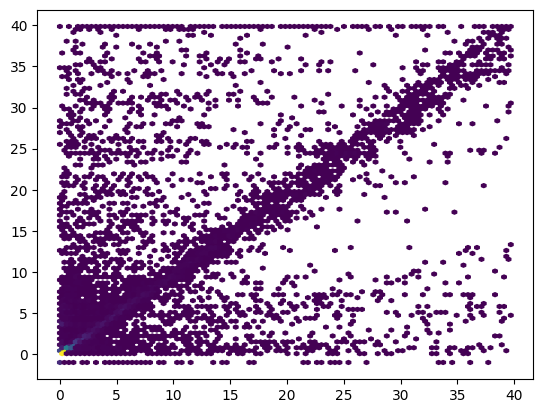

In [119]:
plt.hexbin(
    astro_cat['z'],
    eazy_out.zbest, 
    mincnt = 1
)

# plt.scatter(
#     astro_cat['z'][idx_selected],
#     eazy_out.zbest[idx_selected], 
#     marker = "."
# )

In [ ]:
zbins = np.arange(0, 40, 1.0)
zmids = (zbins[1:] + zbins[:-1])/2.0

magbins = np.arange(10, 40, 1.0)
magmids = (magbins[1:] + magbins[:-1])/2.0

completeness_array = np.zeros(shape = (len(magmids), len(zmids)))
contamination_array = np.zeros(shape = (len(magmids), len(zmids)))

for i in range(len(magmids)):
    for j in range(len(zmids)):

        detect_idx = (astro_cat["recoveredmag"] >= magbins[i]) & (astro_cat["recoveredmag"] < magbins[i+1]) & \
            (eazy_out.zbest >= zbins[j]) & (eazy_out.zbest < zbins[j+1])
        
        true_idx = (astro_cat["detmag"] >= magbins[i]) & (astro_cat["detmag"] < magbins[i+1]) & \
            (astro_cat["z"] >= zbins[j]) & (astro_cat["z"] < zbins[j+1])

        idx_bad_fit = (1 - stats.chi2.cdf(match_chi2[detect_idx], df = Nfluxes[detect_idx] - Ntemplates[detect_idx] - 1.0) < 0.05) | (eazy_out.zbest[detect_idx] == -1) | (astro_cat["detected"][detect_idx] == 0)

        outliers = compute_outliers(
            zphot=eazy_out.zbest[detect_idx][~idx_bad_fit],
            zspec=astro_cat["z"][detect_idx][~idx_bad_fit]
        )

        Nselect = np.sum(~idx_bad_fit) - outliers[1]
        Ntrue = np.sum(true_idx)
        completeness = Nselect / Ntrue
        

        if Ntrue == 0:
            completeness = np.nan
        completeness_array[i,j] = completeness
        completeness_array[i,j] = completeness

/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_1890/3157413248.py:28: RuntimeWarning: invalid value encountered in scalar divide
  completeness = Nselect / Ntrue
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_1890/3157413248.py:28: RuntimeWarning: divide by zero encountered in scalar divide
  completeness = Nselect / Ntrue


In [205]:
completeness_array.shape

(29, 39)

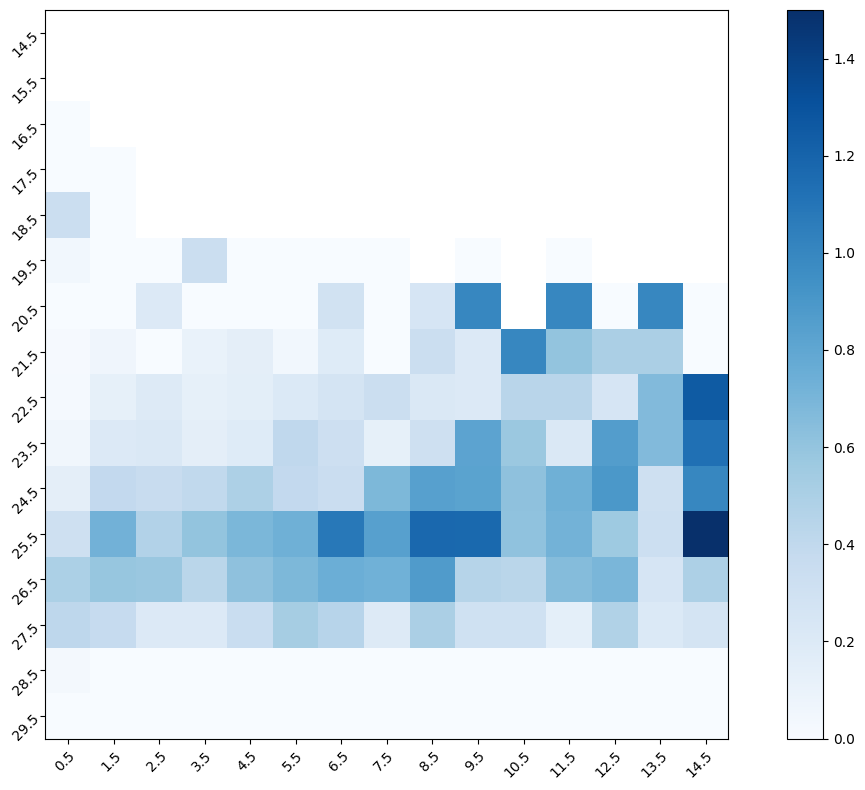

In [206]:
fig, ax = plt.subplots(figsize = (12,8))

mag_ids = np.where((magmids >= 14) & (magmids <= 30))[0]
z_ids = np.where((zmids >= 0) & (zmids <= 15))[0]

im = ax.imshow(
    completeness_array[np.ix_(mag_ids, z_ids)], 
    cmap='Blues'
)

# ax.set_xlim([0,10])
# ax.set_ylim([18,30])
ax.set_yticks(range(len(magmids[mag_ids])), labels=magmids[mag_ids], rotation=45, ha="right", rotation_mode="anchor")
ax.set_xticks(range(len(zmids[z_ids])), labels=zmids[z_ids], rotation=45, ha="right", rotation_mode="anchor")

# ax.set_title("Harvest of local farmers (in tons/year)")
fig.colorbar(im)
fig.tight_layout()
plt.show()
